# 02_06 Heavy Tails: Pareto and Cauchy

**Learning objectives**
- Tell **light-tailed** from **heavy-tailed** distributions, and see why extreme values dominate heavy-tailed data.
- Work with the **Pareto** (power-law tail, the 80/20 rule) and the **Cauchy** (so heavy that it has no mean).
- Derive survival functions, moments (and when they are infinite), quantiles, and the share of the total held by the top fraction.
- Understand why the sample mean of Cauchy data never settles, and why a Normal model can badly understate tail risk.

**Prerequisites:** [02_01 Uniform and Normal](02_01_uniform_normal.ipynb), [02_02 Lognormal](02_02_lognormal.ipynb), [01_06 Zipf and power laws](../../module_01_discrete/notebooks/01_06_zipf_power_laws.ipynb) (the discrete power law).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Survival function** $S(x)=P(X>x)$: the probability of exceeding $x$. The **tail** is how fast $S(x)$ falls to 0.
- **Expected value** $E[X]=\int xf(x)dx$ exists only if the integral converges (absolutely).
- **Law of Large Numbers:** if $E[X]$ exists, the sample mean converges to it.
- **p-series / integral test:** $\int_1^\infty x^{-a}dx$ is finite iff $a>1$.
- **Log-log plot:** a power law $y=Cx^{-a}$ is a straight line of slope $-a$.
- **Lognormal** (02_02) already had a long right tail; heavy tails go further.

## 3. Intuition and story

### 3.1 How fast does the tail fall?
For the **Normal**, $S(x)\approx e^{-x^2/2}$: it collapses so fast that a value 6 standard deviations out is essentially impossible (about 1 in 500 million). For a **power law**, $S(x)\propto x^{-\alpha}$: it falls only polynomially, so enormous values keep happening. Compare the chance of exceeding 10 standard-ish units:

- Normal: $P(Z>10)\approx7.6\times10^{-24}$.
- Cauchy (the heaviest in this lesson): $P(X>10)\approx0.032$, one in thirty.

Heavy-tailed data are dominated by a few giant observations: the richest person owns more than the bottom half, one file is bigger than all the others together, one day's loss wipes out years of profit. The **Pareto principle (80/20 rule)** is one expression of this: about 80 % of the effects come from 20 % of the causes.

### 3.2 Two characters
- **Pareto($\alpha,x_m$):** values above a minimum $x_m$, with tail $S(x)=(x_m/x)^\alpha$. Smaller $\alpha$ means a heavier tail. Models wealth, city sizes, file sizes, insurance losses, popularity.
- **Cauchy($x_0,\gamma$):** a bell-like curve but with tails so fat that the **mean does not exist**. It arises as the ratio of two Normals, and in physics as resonance line shapes.

The picture below compares the three tails. On a **log scale** the Normal's survival function plummets while the Pareto and Cauchy decline slowly.

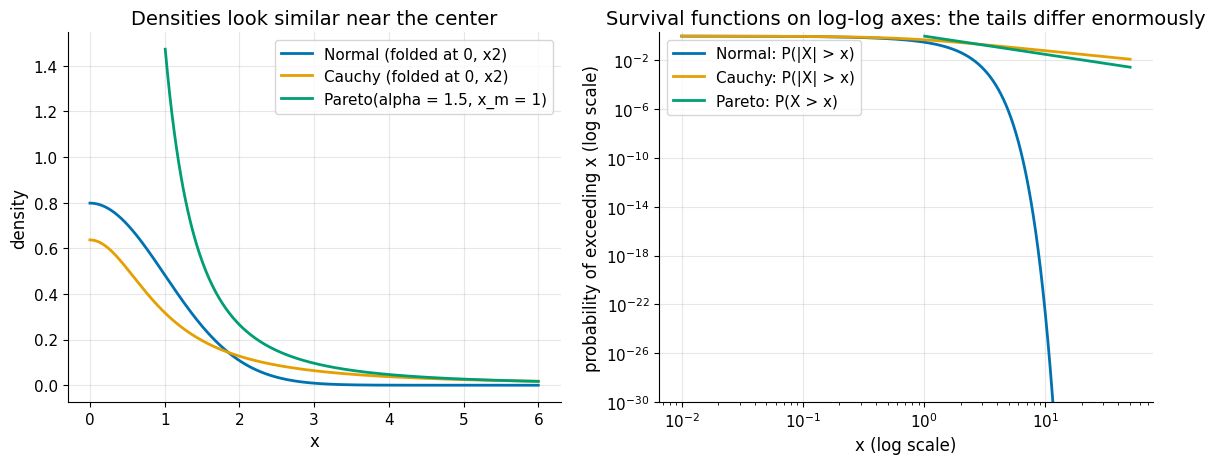

In [2]:
x_axis = np.linspace(0.01, 50, 2000)
normal = stats.norm(0, 1)
cauchy = stats.cauchy(0, 1)
pareto = stats.pareto(b=1.5, scale=1)            # alpha = 1.5, x_m = 1

fig, (ax_pdf, ax_sf) = plt.subplots(1, 2, figsize=(14, 4.8))
grid = np.linspace(0, 6, 400)
ax_pdf.plot(grid, 2 * normal.pdf(grid), color=COLORS[0], linewidth=2, label="Normal (folded at 0, x2)")
ax_pdf.plot(grid, 2 * cauchy.pdf(grid), color=COLORS[1], linewidth=2, label="Cauchy (folded at 0, x2)")
ax_pdf.plot(grid[grid >= 1], pareto.pdf(grid[grid >= 1]), color=COLORS[2], linewidth=2, label="Pareto(alpha = 1.5, x_m = 1)")
ax_pdf.set_title("Densities look similar near the center")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()

ax_sf.loglog(x_axis, 2 * normal.sf(x_axis), color=COLORS[0], linewidth=2, label="Normal: P(|X| > x)")
ax_sf.loglog(x_axis, 2 * cauchy.sf(x_axis), color=COLORS[1], linewidth=2, label="Cauchy: P(|X| > x)")
ax_sf.loglog(x_axis[x_axis >= 1], pareto.sf(x_axis[x_axis >= 1]), color=COLORS[2], linewidth=2, label="Pareto: P(X > x)")
ax_sf.set_ylim(1e-30, 2)
ax_sf.set_title("Survival functions on log-log axes: the tails differ enormously")
ax_sf.set_xlabel("x (log scale)")
ax_sf.set_ylabel("probability of exceeding x (log scale)")
ax_sf.legend()
plt.show()

**In plain words.** Near the center you cannot tell these distributions apart. In the tail, the Normal essentially forbids large values while the power laws allow them regularly. When you model money, sizes or losses, the tail is what matters.

## 4. Formal definition

**Pareto($\alpha,x_m$):** support $x\ge x_m>0$; shape (tail index) $\alpha>0$.
$$f(x)=\frac{\alpha\,x_m^\alpha}{x^{\alpha+1}},\qquad S(x)=\Big(\frac{x_m}x\Big)^\alpha,\qquad F(x)=1-\Big(\frac{x_m}x\Big)^\alpha.$$

**Cauchy($x_0,\gamma$):** support all real numbers; location $x_0$ (the median and mode) and scale $\gamma>0$.
$$f(x)=\frac1{\pi\gamma\Big[1+\big(\frac{x-x_0}\gamma\big)^2\Big]},\qquad F(x)=\frac12+\frac1\pi\arctan\!\Big(\frac{x-x_0}\gamma\Big).$$

**`scipy`:** `stats.pareto(b=alpha, scale=x_m)` and `stats.cauchy(loc=x0, scale=gamma)`. Note that the Cauchy's "location" and "scale" are **not** a mean and an SD (neither exists).

## 5. Derivations

### 5.1 Pareto: normalization, CDF and quantiles
$\int_{x_m}^\infty\alpha x_m^\alpha x^{-\alpha-1}dx=\big[-x_m^\alpha x^{-\alpha}\big]_{x_m}^\infty=1$, and $S(x)=(x_m/x)^\alpha$. Solving $S(x_p)=1-p$:
$$x_p=x_m(1-p)^{-1/\alpha},\qquad\text{median}=x_m2^{1/\alpha}.$$

### 5.2 Pareto: moments and when they are infinite
$$E[X^n]=\int_{x_m}^\infty x^n\frac{\alpha x_m^\alpha}{x^{\alpha+1}}dx=\alpha x_m^\alpha\int_{x_m}^\infty x^{n-\alpha-1}dx,$$
which converges only if $n<\alpha$, giving $E[X^n]=\dfrac{\alpha x_m^n}{\alpha-n}$. Therefore:
- **$\alpha\le1$:** the mean is **infinite**.
- **$1<\alpha\le2$:** the mean $\dfrac{\alpha x_m}{\alpha-1}$ is finite but the variance is **infinite**.
- **$\alpha>2$:** variance $\dfrac{\alpha x_m^2}{(\alpha-1)^2(\alpha-2)}$.

**In plain words.** The smaller the tail index, the fewer moments exist. Real data with $\alpha$ near 1 to 2 (wealth, city sizes) have averages that are unstable and variances that mean nothing.

### 5.3 Pareto and the Exponential
If $X\sim\text{Pareto}(\alpha,x_m)$ then $\ln(X/x_m)\sim\text{Exponential}(\alpha)$, because $P(\ln(X/x_m)>y)=P(X>x_me^y)=e^{-\alpha y}$. So Pareto is the "exponential of an exponential", and a log-log survival plot is a straight line of slope $-\alpha$ (the tail index estimate).

### 5.4 The 80/20 rule (share of the total held by the top)
Let $\alpha>1$. The threshold exceeded by the top fraction $q$ of the population is $x_q=x_mq^{-1/\alpha}$. The total held by those above $x_q$ is $\int_{x_q}^\infty x\,f(x)dx=\dfrac{\alpha x_m^\alpha}{\alpha-1}x_q^{1-\alpha}$, and the overall total is $E[X]=\dfrac{\alpha x_m}{\alpha-1}$ per person. The **share held by the top fraction $q$** is
$$\text{share}(q)=\frac{x_q^{1-\alpha}x_m^{\alpha-1}}{1}=q^{(\alpha-1)/\alpha}.$$
For the 80/20 rule, $q=0.2$ must give 0.8: $0.2^{(\alpha-1)/\alpha}=0.8\Rightarrow\frac{\alpha-1}\alpha=\frac{\ln0.8}{\ln0.2}=0.1387\Rightarrow\alpha=\frac1{1-0.1387}=1.161$.
The **Gini coefficient** of a Pareto is $G=\dfrac1{2\alpha-1}$.

### 5.5 Cauchy: normalization and CDF
$\int\frac{dx}{\pi\gamma(1+u^2)}$ with $u=(x-x_0)/\gamma$ is $\frac1\pi\arctan u$, going from $-\frac\pi2$ to $\frac\pi2$: total 1. Hence $F(x)=\frac12+\frac1\pi\arctan(u)$, and the quantile function is $x_p=x_0+\gamma\tan\big(\pi(p-\tfrac12)\big)$ (also the way to simulate it).

### 5.6 Cauchy: why there is no mean
$\int|x|f(x)dx\ \propto\ \int^\infty\frac{x}{1+x^2}dx=\tfrac12\ln(1+x^2)\to\infty$. The integral diverges, so $E[X]$ is undefined. (By symmetry the "principal value" is 0, but that is not a mean: splitting the integral differently gives other answers.) The variance and all higher moments are also infinite.

### 5.7 Cauchy as a ratio of Normals
If $Z_1,Z_2$ are independent $N(0,1)$ then $Z_1/Z_2\sim\text{Cauchy}(0,1)$. When the denominator is near 0 the ratio explodes, which is the source of the heavy tails. Also $\tan\Theta$ for $\Theta\sim\text{Uniform}(-\frac\pi2,\frac\pi2)$ is Cauchy (the "lighthouse problem", Example 2).

### 5.8 The sample mean of Cauchy data is just as noisy as one observation
The characteristic function of a Cauchy($0,\gamma$) is $E[e^{itX}]=e^{-\gamma|t|}$. For the mean of $n$ independent copies, $E[e^{it\bar X}]=\big(e^{-\gamma|t|/n}\big)^n=e^{-\gamma|t|}$: **the average of $n$ Cauchy values is again Cauchy with the same scale**. Averaging does not help: the Law of Large Numbers and the Central Limit Theorem both fail because the mean does not exist. The sample **median**, however, does converge (to $x_0$).

## 6. Properties and relationships

- **Light vs heavy tails:** a distribution is heavy-tailed if its tail decays slower than any exponential. Normal, Exponential, Gamma, Weibull (with $k\ge1$) are light-tailed; Pareto, Cauchy, Student-t with few degrees of freedom, and sometimes the Lognormal, are heavy.
- **Cauchy = Student-t with 1 degree of freedom** (02_08).
- **Pareto and Zipf:** the discrete power law (01_06) and the continuous Pareto describe the same phenomenon.
- **Stable laws:** sums of Cauchy are Cauchy and sums of Normals are Normal; both are *stable* distributions.
- **Truncation matters in practice:** real data have a finite maximum (a country's total wealth), so power laws usually fit only over a range.
- **Estimating alpha:** the maximum-likelihood estimator for Pareto is $\hat\alpha=n/\sum\ln(x_i/x_m)$, the Exponential rate of the logs.

## 7. 2D visuals

### 7.1 Pareto PDF, CDF and survival
Pareto(alpha = 2, x_m = 1): a jump up to the maximum density at x_m, then a power-law decay. The right panel shows the survival on log-log axes: a straight line of slope -alpha.

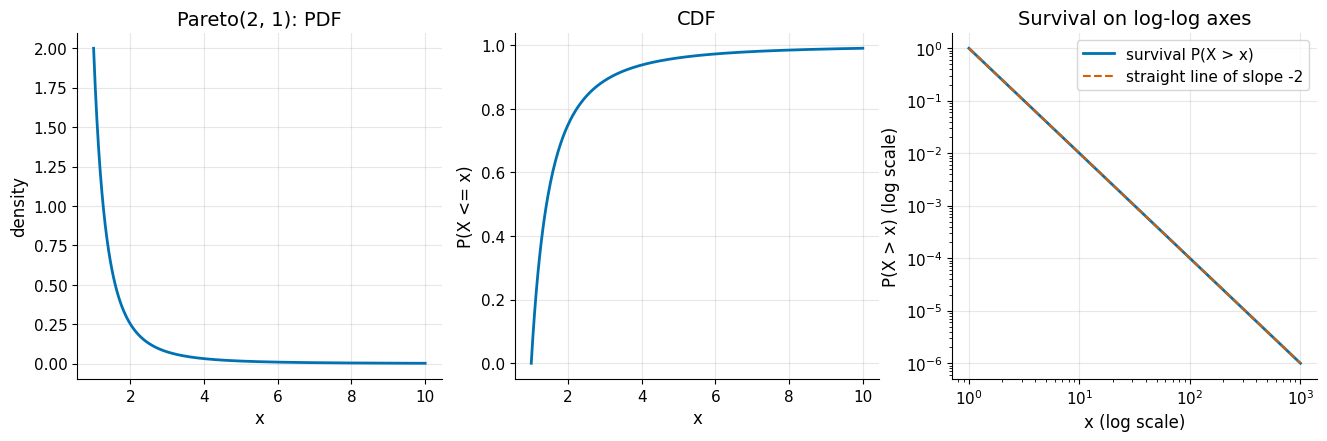

In [3]:
alpha, x_min = 2.0, 1.0
dist = stats.pareto(b=alpha, scale=x_min)
x_axis = np.linspace(1, 10, 400)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].set_title("Pareto(2, 1): PDF")
axes[0].set_xlabel("x")
axes[0].set_ylabel("density")

axes[1].plot(x_axis, dist.cdf(x_axis), color=MAIN, linewidth=2)
axes[1].set_title("CDF")
axes[1].set_xlabel("x")
axes[1].set_ylabel("P(X <= x)")

x_wide = np.logspace(0, 3, 300)
axes[2].loglog(x_wide, dist.sf(x_wide), color=MAIN, linewidth=2, label="survival P(X > x)")
axes[2].loglog(x_wide, x_wide ** (-alpha), "--", color=HIGHLIGHT, label="straight line of slope -2")
axes[2].set_title("Survival on log-log axes")
axes[2].set_xlabel("x (log scale)")
axes[2].set_ylabel("P(X > x) (log scale)")
axes[2].legend()
plt.show()

### 7.2 Effect of the tail index alpha
Smaller alpha means a heavier tail: more probability far to the right (look at the survival functions on log-log axes).

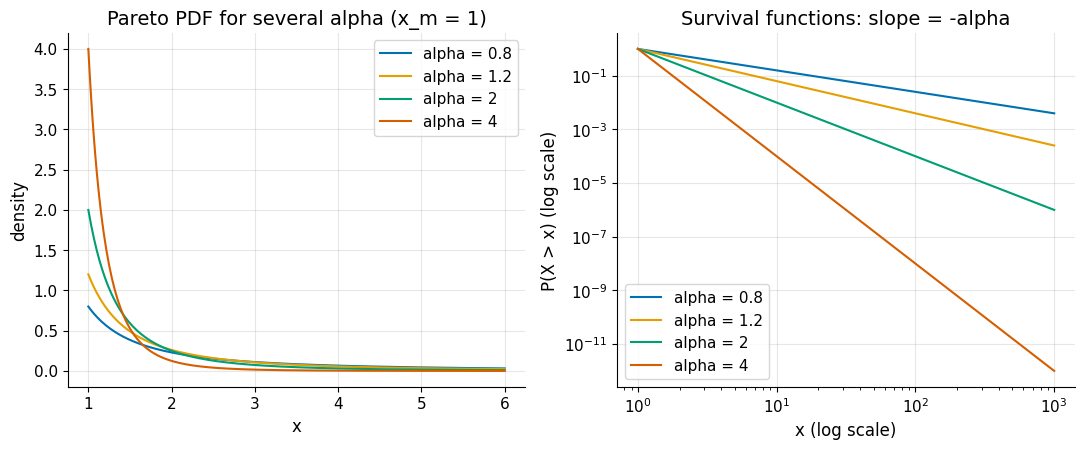

In [4]:
x_axis = np.logspace(0, 3, 400)
fig, (ax_pdf, ax_sf) = plt.subplots(1, 2, figsize=(13, 4.6))
grid = np.linspace(1, 6, 300)
for a, color in zip([0.8, 1.2, 2, 4], COLORS):
    ax_pdf.plot(grid, stats.pareto(a).pdf(grid), color=color, label=f"alpha = {a}")
    ax_sf.loglog(x_axis, stats.pareto(a).sf(x_axis), color=color, label=f"alpha = {a}")
ax_pdf.set_title("Pareto PDF for several alpha (x_m = 1)")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_sf.set_title("Survival functions: slope = -alpha")
ax_sf.set_xlabel("x (log scale)")
ax_sf.set_ylabel("P(X > x) (log scale)")
ax_sf.legend()
plt.show()

### 7.3 Cauchy PDF and the effect of gamma
The Cauchy looks like a bell but with a sharper peak and much fatter tails. The scale gamma is the half-width at half-maximum (not a standard deviation).

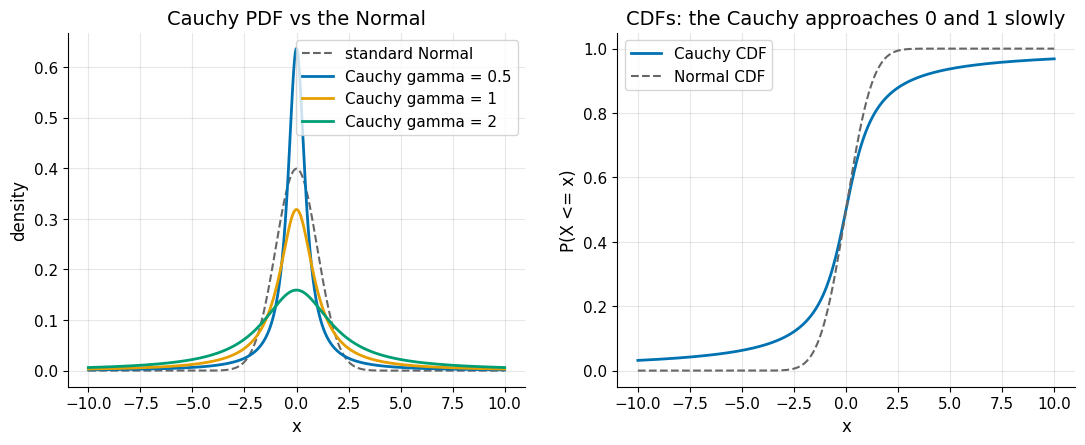

In [5]:
x_axis = np.linspace(-10, 10, 800)
fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_pdf.plot(x_axis, stats.norm(0, 1).pdf(x_axis), "--", color=NEUTRAL, label="standard Normal")
for gamma_value, color in zip([0.5, 1, 2], COLORS):
    ax_pdf.plot(x_axis, stats.cauchy(0, gamma_value).pdf(x_axis), color=color, linewidth=2, label=f"Cauchy gamma = {gamma_value}")
ax_pdf.set_title("Cauchy PDF vs the Normal")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()

ax_cdf.plot(x_axis, stats.cauchy(0, 1).cdf(x_axis), color=MAIN, linewidth=2, label="Cauchy CDF")
ax_cdf.plot(x_axis, stats.norm(0, 1).cdf(x_axis), "--", color=NEUTRAL, label="Normal CDF")
ax_cdf.set_title("CDFs: the Cauchy approaches 0 and 1 slowly")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
ax_cdf.legend()
plt.show()

### 7.4 The 80/20 rule: the Lorenz curve
The Lorenz curve shows the share of the total held by the bottom fraction of the population. For a Pareto, the share of the *top* fraction q is q^((alpha-1)/alpha). With alpha = 1.16 the top 20 % hold about 80 %.

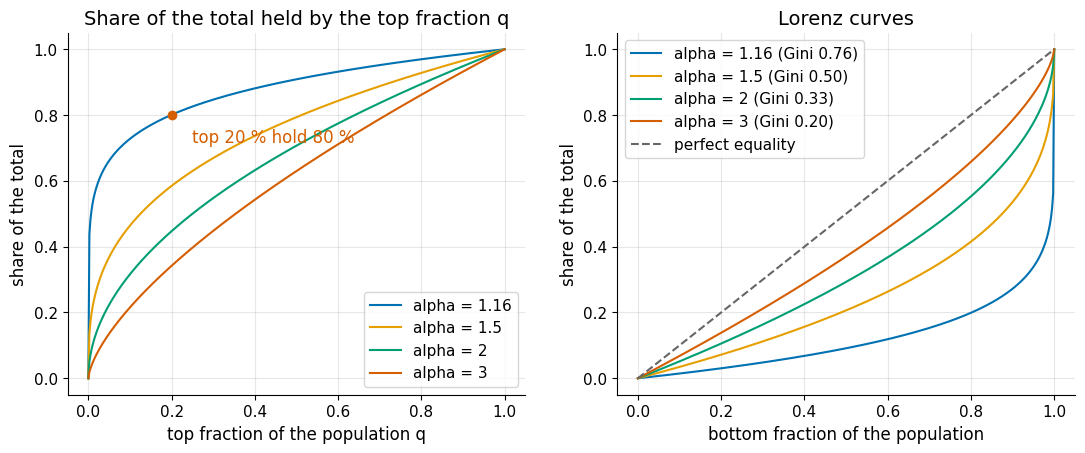

In [6]:
q_axis = np.linspace(0, 1, 400)
fig, (ax_top, ax_lorenz) = plt.subplots(1, 2, figsize=(13, 4.7))
for a, color in zip([1.16, 1.5, 2, 3], COLORS):
    top_share = q_axis ** ((a - 1) / a)
    ax_top.plot(q_axis, top_share, color=color, label=f"alpha = {a}")
    ax_lorenz.plot(q_axis, 1 - (1 - q_axis) ** ((a - 1) / a), color=color, label=f"alpha = {a} (Gini {1 / (2 * a - 1):.2f})")
ax_top.plot([0.2], [0.8], "o", color=HIGHLIGHT)
ax_top.annotate("top 20 % hold 80 %", (0.2, 0.8), textcoords="offset points", xytext=(15, -20), color=HIGHLIGHT, fontsize=12)
ax_top.set_title("Share of the total held by the top fraction q")
ax_top.set_xlabel("top fraction of the population q")
ax_top.set_ylabel("share of the total")
ax_top.legend()

ax_lorenz.plot([0, 1], [0, 1], "--", color=NEUTRAL, label="perfect equality")
ax_lorenz.set_title("Lorenz curves")
ax_lorenz.set_xlabel("bottom fraction of the population")
ax_lorenz.set_ylabel("share of the total")
ax_lorenz.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: Pareto PDF over (x, alpha), x_m = 1
A wall at x = 1 (the density there is alpha) that decays faster for large alpha.

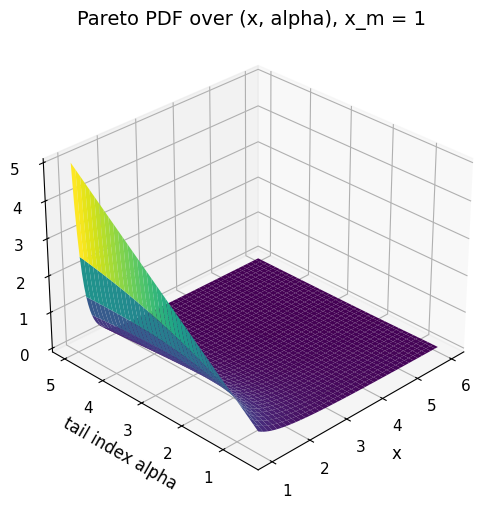

In [7]:
x_values = np.linspace(1, 6, 120)
alpha_values = np.linspace(0.5, 5, 40)
X, A = np.meshgrid(x_values, alpha_values)
Z = A / X ** (A + 1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, A, Z, cmap="viridis", edgecolor="none")
ax.set_title("Pareto PDF over (x, alpha), x_m = 1")
ax.set_xlabel("x")
ax.set_ylabel("tail index alpha")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-135)
plt.show()

### 8.2 Static: Cauchy PDF over (x, gamma)
Small gamma gives a tall narrow peak; large gamma spreads the mass, and the tails stay fat for every gamma.

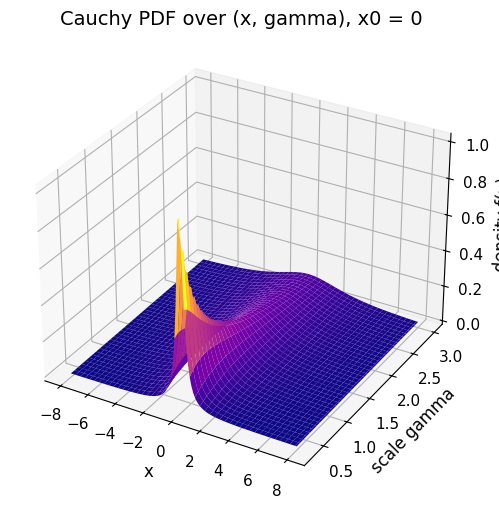

In [8]:
x_values2 = np.linspace(-8, 8, 140)
gamma_values = np.linspace(0.3, 3, 40)
X2, G = np.meshgrid(x_values2, gamma_values)
Z2 = 1 / (np.pi * G * (1 + (X2 / G) ** 2))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X2, G, Z2, cmap="plasma", edgecolor="none")
ax.set_title("Cauchy PDF over (x, gamma), x0 = 0")
ax.set_xlabel("x")
ax.set_ylabel("scale gamma")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.3 Interactive Plotly version
The Pareto surface of 8.1; drag to rotate.

In [9]:
fig = go.Figure(go.Surface(x=x_values, y=alpha_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Pareto PDF over (x, alpha), x_m = 1", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="tail index alpha", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Pareto sampling and the tail check
We sample with the quantile function x_m * U^(-1/alpha) (inverse-transform sampling, section 5.1) and check that the empirical survival function lies on the theoretical straight line.

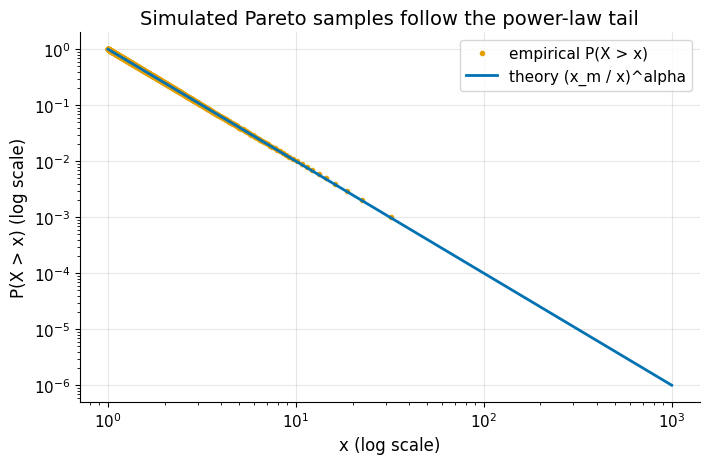

largest of 200,000 samples: 276 (the maximum of n draws is of order n^(1/alpha) = 447, but it varies a lot from run to run)
maximum-likelihood estimate of alpha = 1.999 (true 2)


In [10]:
alpha, x_min = 2.0, 1.0
uniforms = rng.uniform(size=200_000)
samples = x_min * uniforms ** (-1 / alpha)

sorted_samples = np.sort(samples)
empirical_survival = 1 - np.arange(1, len(sorted_samples) + 1) / len(sorted_samples)
keep = empirical_survival > 0
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(sorted_samples[keep][::200], empirical_survival[keep][::200], ".", color=SIM, label="empirical P(X > x)")
ax.loglog(x_wide, dist.sf(x_wide), color=MAIN, linewidth=2, label="theory (x_m / x)^alpha")
ax.set_title("Simulated Pareto samples follow the power-law tail")
ax.set_xlabel("x (log scale)")
ax.set_ylabel("P(X > x) (log scale)")
ax.legend()
plt.show()
print(f"largest of {len(samples):,} samples: {samples.max():.0f} (the maximum of n draws is of order n^(1/alpha) = {x_min * len(samples) ** (1 / alpha):.0f}, but it varies a lot from run to run)")
alpha_hat = len(samples) / np.log(samples / x_min).sum()
print(f"maximum-likelihood estimate of alpha = {alpha_hat:.3f} (true 2)")

### 9.2 The running mean for different tail indices
The Law of Large Numbers needs a finite mean. For alpha = 3 the running mean settles quickly. For alpha = 1.5 (finite mean, infinite variance) it is slow and jumpy. For alpha = 0.9 (infinite mean) it keeps growing: it never settles.

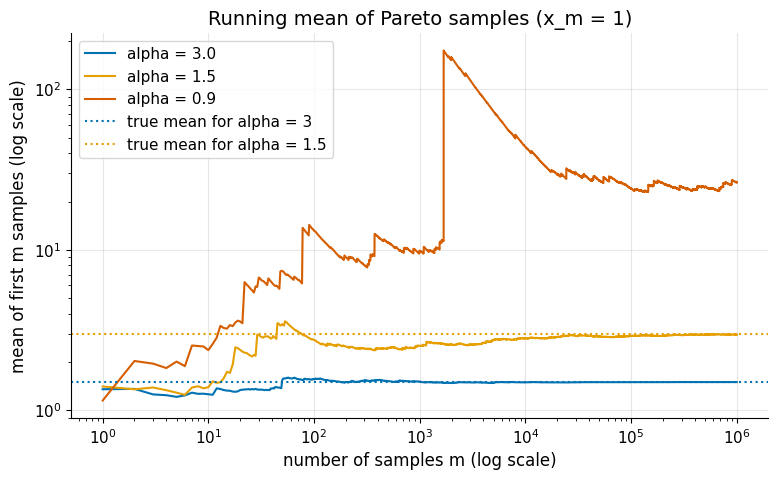

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for a, color in zip([3.0, 1.5, 0.9], [COLORS[0], COLORS[1], COLORS[3]]):
    draws = rng.uniform(size=1_000_000) ** (-1 / a)
    running_mean = np.cumsum(draws) / np.arange(1, len(draws) + 1)
    ax.loglog(np.arange(1, len(draws) + 1), running_mean, color=color, label=f"alpha = {a}")
ax.axhline(stats.pareto(3).mean(), color=COLORS[0], linestyle=":", label="true mean for alpha = 3")
ax.axhline(stats.pareto(1.5).mean(), color=COLORS[1], linestyle=":", label="true mean for alpha = 1.5")
ax.set_title("Running mean of Pareto samples (x_m = 1)")
ax.set_xlabel("number of samples m (log scale)")
ax.set_ylabel("mean of first m samples (log scale)")
ax.legend()
plt.show()

### 9.3 The Cauchy running mean never settles, but the median does
We track the running mean and the running median of Cauchy and Normal samples. The Normal mean converges; the Cauchy mean keeps jumping whenever a huge value appears; the Cauchy median converges to 0.

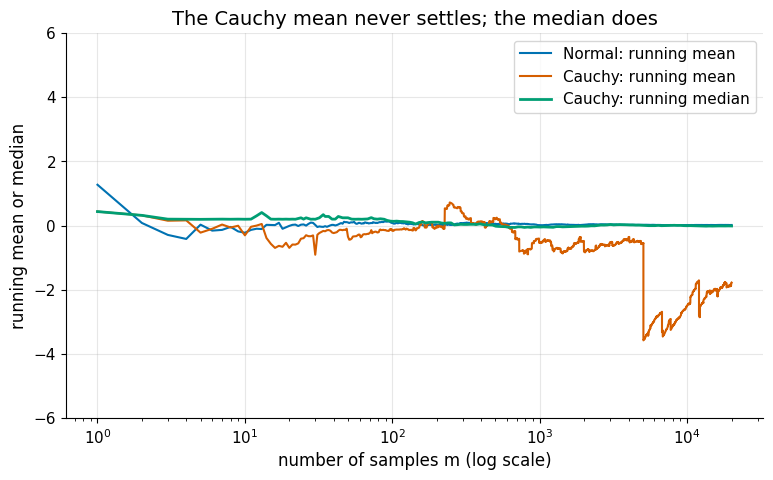

In [12]:
m_values = np.arange(1, 20_001)
cauchy_draws = rng.standard_cauchy(size=len(m_values))
normal_draws = rng.normal(size=len(m_values))
running_mean_cauchy = np.cumsum(cauchy_draws) / m_values
running_mean_normal = np.cumsum(normal_draws) / m_values
checkpoints = np.unique(np.logspace(0, np.log10(len(m_values)), 200).astype(int))
running_median_cauchy = np.array([np.median(cauchy_draws[:m]) for m in checkpoints])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(m_values, running_mean_normal, color=COLORS[0], label="Normal: running mean")
ax.plot(m_values, running_mean_cauchy, color=HIGHLIGHT, label="Cauchy: running mean")
ax.plot(checkpoints, running_median_cauchy, color=COLORS[2], linewidth=2, label="Cauchy: running median")
ax.set_xscale("log")
ax.set_ylim(-6, 6)
ax.set_title("The Cauchy mean never settles; the median does")
ax.set_xlabel("number of samples m (log scale)")
ax.set_ylabel("running mean or median")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [13]:
p = stats.pareto(b=1.5, scale=10_000)         # alpha = 1.5, x_m = 10,000
print("pareto sf(100000)    P(X > 100,000):", round(p.sf(100_000), 5))
print("pareto cdf(20000)    :", round(p.cdf(20_000), 5))
print("pareto ppf(0.99)     99th percentile:", round(p.ppf(0.99)))
print("pareto mean, median  :", round(p.mean()), round(p.median()))
print("pareto var (alpha <= 2 -> infinite):", p.var())
print("pareto rvs(3)        :", p.rvs(size=3, random_state=1).round(0))

c = stats.cauchy(loc=0, scale=1)
print("cauchy pdf(0), cdf(1), sf(10):", round(c.pdf(0), 5), round(c.cdf(1), 5), round(c.sf(10), 5))
print("cauchy mean, var     :", c.mean(), c.var(), "(undefined / infinite)")
print("cauchy median, ppf(0.75):", c.median(), round(c.ppf(0.75), 4), "(ppf(0.75) = gamma, a robust scale)")
print("cauchy interval(0.5) :", np.round(c.interval(0.5), 3))

pareto sf(100000)    P(X > 100,000): 0.03162
pareto cdf(20000)    : 0.64645
pareto ppf(0.99)     99th percentile: 215443
pareto mean, median  : 30000 15874
pareto var (alpha <= 2 -> infinite): inf
pareto rvs(3)        : [14330. 23383. 10001.]
cauchy pdf(0), cdf(1), sf(10): 0.31831 0.75 0.03173
cauchy mean, var     : nan nan (undefined / infinite)
cauchy median, ppf(0.75): 0.0 1.0 (ppf(0.75) = gamma, a robust scale)
cauchy interval(0.5) : [-1.  1.]


**Fitting:** for the Pareto, the maximum-likelihood estimates are $\hat x_m=\min x_i$ and $\hat\alpha=n/\sum\ln(x_i/\hat x_m)$. `stats.pareto.fit(data, floc=0)` does the same numerically. For the Cauchy, `stats.cauchy.fit` works but use the median and the interquartile range as robust starting guesses.

In [14]:
data = 10_000 * rng.uniform(size=5000) ** (-1 / 1.5)
x_min_hat = data.min()
alpha_hat = len(data) / np.log(data / x_min_hat).sum()
b_hat, loc_hat, scale_hat = stats.pareto.fit(data, floc=0)
print(f"true alpha = 1.5, x_m = 10,000 -> direct MLE alpha = {alpha_hat:.3f}, x_m = {x_min_hat:.0f}; scipy fit alpha = {b_hat:.3f}, x_m = {scale_hat:.0f}")
cauchy_data = stats.cauchy(3, 2).rvs(size=5000, random_state=2)
q25, q50, q75 = np.percentile(cauchy_data, [25, 50, 75])
print(f"Cauchy(3, 2): median = {q50:.2f} (location), half the IQR = {(q75 - q25) / 2:.2f} (scale)")

true alpha = 1.5, x_m = 10,000 -> direct MLE alpha = 1.503, x_m = 10001; scipy fit alpha = 1.503, x_m = 10001
Cauchy(3, 2): median = 2.89 (location), half the IQR = 1.98 (scale)


## 11. Real-world worked examples

---
### Example 1 (main): wealth distribution

**Scenario (illustrative numbers).** In a population, wealth above a minimum of **10,000** follows a Pareto distribution with tail index **$\alpha=1.5$**.

**Questions**
1. What fraction of people have more than **100,000**?
2. What are the **mean and the median** wealth? Is the variance finite?
3. What share of the total wealth is held by the **top 1 %**?
4. For the 80/20 rule (top 20 % hold 80 %), which $\alpha$ is needed?

### 11.1 By hand
**Q1.** $S(100{,}000)=\big(\tfrac{10{,}000}{100{,}000}\big)^{1.5}=0.1^{1.5}=0.03162$ (about 3.2 %).

**Q2.** Mean $=\dfrac{\alpha x_m}{\alpha-1}=\dfrac{1.5\times10{,}000}{0.5}=30{,}000$. Median $=x_m2^{1/\alpha}=10{,}000\times2^{0.6667}=15{,}874$. The mean is almost twice the median. Since $\alpha=1.5\le2$ the variance is **infinite**.

**Q3.** Top share $=q^{(\alpha-1)/\alpha}$ with $q=0.01$: $0.01^{0.5/1.5}=0.01^{1/3}=0.2154$ (21.5 % of all wealth held by the top 1 %).

**Q4.** $\alpha=\dfrac1{1-\ln0.8/\ln0.2}=\dfrac1{1-0.1387}=1.161$.

In [15]:
import math

alpha_wealth, minimum_wealth = 1.5, 10_000

p_over_100k_hand = (minimum_wealth / 100_000) ** alpha_wealth
mean_hand = alpha_wealth * minimum_wealth / (alpha_wealth - 1)
median_hand = minimum_wealth * 2 ** (1 / alpha_wealth)
top_1_percent_share_hand = 0.01 ** ((alpha_wealth - 1) / alpha_wealth)
alpha_80_20_hand = 1 / (1 - math.log(0.8) / math.log(0.2))
print(f"P(>100k) = {p_over_100k_hand:.5f}, mean = {mean_hand:,.0f}, median = {median_hand:,.0f}, top 1% share = {top_1_percent_share_hand:.4f}, alpha for 80/20 = {alpha_80_20_hand:.4f}")

P(>100k) = 0.03162, mean = 30,000, median = 15,874, top 1% share = 0.2154, alpha for 80/20 = 1.1610


### 11.2 In code with `scipy`, and the asserts
The share of the top 1 % is computed independently by numerical integration of x * f(x) above the 99th percentile.

In [16]:
wealth = stats.pareto(b=alpha_wealth, scale=minimum_wealth)

assert np.isclose(p_over_100k_hand, wealth.sf(100_000))
assert np.isclose(mean_hand, wealth.mean())
assert np.isclose(median_hand, wealth.median())
assert np.isinf(wealth.var())

threshold_99 = wealth.ppf(0.99)
upper_values = np.logspace(np.log10(threshold_99), 14, 200_000)           # integrate far into the tail
integrand = upper_values * wealth.pdf(upper_values)
top_total = np.trapezoid(integrand, upper_values)
top_1_percent_share_code = top_total / wealth.mean()
print(f"share of the top 1 % by numerical integration = {top_1_percent_share_code:.4f} (formula {top_1_percent_share_hand:.4f})")
assert np.isclose(top_1_percent_share_code, top_1_percent_share_hand, atol=0.005)

share_at_alpha_80_20 = 0.2 ** ((alpha_80_20_hand - 1) / alpha_80_20_hand)
assert np.isclose(share_at_alpha_80_20, 0.8)
print(f"P(wealth > 100,000) = {wealth.sf(100_000):.5f}; mean {wealth.mean():,.0f}; median {wealth.median():,.0f}; 99th percentile {threshold_99:,.0f}")

share of the top 1 % by numerical integration = 0.2154 (formula 0.2154)
P(wealth > 100,000) = 0.03162; mean 30,000; median 15,874; 99th percentile 215,443


### 11.3 Verify by simulation
Simulate 1 million people with inverse-transform sampling and compute the same quantities. The sample mean is slow to converge (infinite variance), so allow a looser tolerance.

In [17]:
simulated = minimum_wealth * rng.uniform(size=1_000_000) ** (-1 / alpha_wealth)
print(f"P(>100k): exact {wealth.sf(100_000):.5f} simulated {np.mean(simulated > 100_000):.5f}")
print(f"median:   exact {wealth.median():,.0f} simulated {np.median(simulated):,.0f}")
print(f"mean:     exact {wealth.mean():,.0f} simulated {simulated.mean():,.0f} (noisy)")
sorted_wealth = np.sort(simulated)[::-1]
top_1_share_simulated = sorted_wealth[:10_000].sum() / sorted_wealth.sum()
print(f"top 1 % share: exact {top_1_percent_share_hand:.3f} simulated {top_1_share_simulated:.3f} (noisy)")
assert abs(np.mean(simulated > 100_000) - wealth.sf(100_000)) < 0.001
assert abs(np.median(simulated) / wealth.median() - 1) < 0.01

P(>100k): exact 0.03162 simulated 0.03178
median:   exact 15,874 simulated 15,870
mean:     exact 30,000 simulated 30,089 (noisy)
top 1 % share: exact 0.215 simulated 0.217 (noisy)


### 11.4 Plots with the regions marked

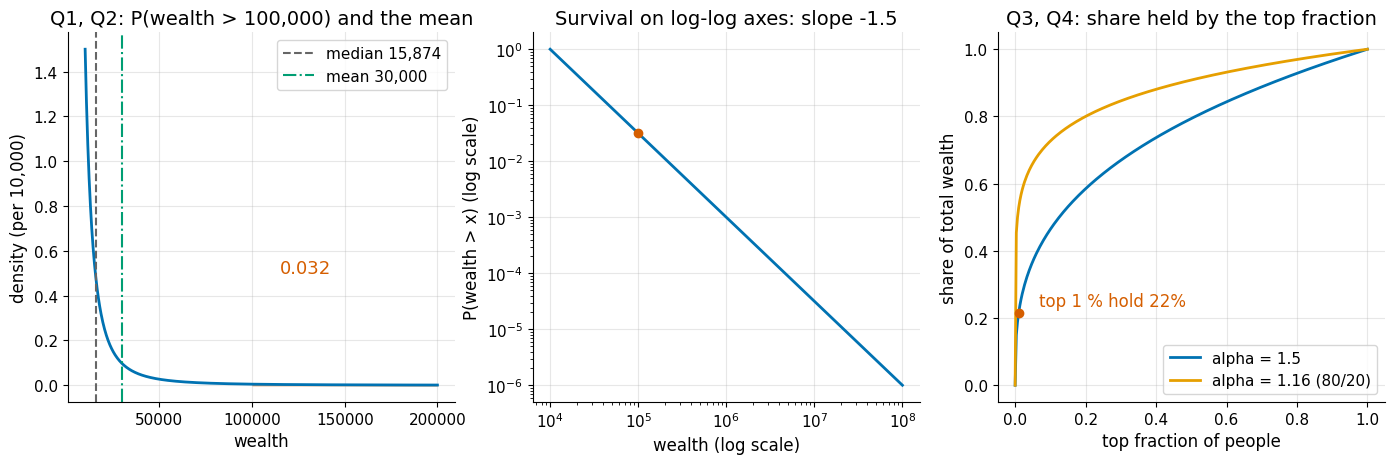

In [18]:
x_axis = np.linspace(10_000, 200_000, 800)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

tail = x_axis >= 100_000
axes[0].plot(x_axis, wealth.pdf(x_axis) * 1e4, color=MAIN, linewidth=2)
axes[0].fill_between(x_axis[tail], wealth.pdf(x_axis[tail]) * 1e4, color=HIGHLIGHT, alpha=0.5)
axes[0].axvline(wealth.median(), color=NEUTRAL, linestyle="--", label=f"median {wealth.median():,.0f}")
axes[0].axvline(wealth.mean(), color=COLORS[2], linestyle="-.", label=f"mean {wealth.mean():,.0f}")
axes[0].set_title("Q1, Q2: P(wealth > 100,000) and the mean")
axes[0].text(115_000, 0.5, f"{wealth.sf(100_000):.3f}", color=HIGHLIGHT, fontsize=13)
axes[0].set_xlabel("wealth")
axes[0].set_ylabel("density (per 10,000)")
axes[0].legend()

x_wide = np.logspace(4, 8, 300)
axes[1].loglog(x_wide, wealth.sf(x_wide), color=MAIN, linewidth=2)
axes[1].plot([100_000], [wealth.sf(100_000)], "o", color=HIGHLIGHT)
axes[1].set_title("Survival on log-log axes: slope -1.5")
axes[1].set_xlabel("wealth (log scale)")
axes[1].set_ylabel("P(wealth > x) (log scale)")

q_axis = np.linspace(0, 1, 300)
axes[2].plot(q_axis, q_axis ** ((alpha_wealth - 1) / alpha_wealth), color=MAIN, linewidth=2, label="alpha = 1.5")
axes[2].plot(q_axis, q_axis ** ((alpha_80_20_hand - 1) / alpha_80_20_hand), color=COLORS[1], linewidth=2, label="alpha = 1.16 (80/20)")
axes[2].plot([0.01], [top_1_percent_share_hand], "o", color=HIGHLIGHT)
axes[2].annotate(f"top 1 % hold {top_1_percent_share_hand:.0%}", (0.01, top_1_percent_share_hand), textcoords="offset points", xytext=(15, 5), color=HIGHLIGHT, fontsize=12)
axes[2].set_title("Q3, Q4: share held by the top fraction")
axes[2].set_xlabel("top fraction of people")
axes[2].set_ylabel("share of total wealth")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- About **3 % of people exceed 100,000** (10 times the minimum), yet the **mean wealth (30,000) is twice the median (15,900)**: a few huge fortunes pull the average up. Quote the median for a "typical" person.
- With alpha = 1.5 the **top 1 % hold about 22 % of all wealth**. For the 80/20 split a heavier tail (alpha = 1.16) is needed.
- Because the variance is infinite, **sample averages and standard deviations of such data are unreliable**: the sample mean in 11.3 happens to land close to 30,000, but in other runs it can be far off (see the running means in 9.2).
- **Decision for policy or modelling:** use medians, quantiles and tail indices (log-log survival plots), not means and SDs. Budget for the rare giant (a large insurance claim, a huge customer), because it will happen.

---
### Example 2: the lighthouse and the Cauchy

**Scenario.** A lighthouse is 1 km out at sea and its beam points in a **uniformly random direction** as it spins. A point on the straight shore (the $x$ axis, at distance 1 from the lighthouse) is lit at position $x=	an\Theta$ where $\Theta\sim	ext{Uniform}(-\pi/2,\pi/2)$. This position is **Cauchy(0, 1)**.

**Questions:** (a) the probability that the lit point is more than 10 km from the closest point; (b) the probability it lies within 1 km; (c) what happens to the **average** of the lit positions over many flashes?

**By hand.** (a) $P(|X|>10)=2ig(1-F(10)ig)=1-rac2\pirctan10=1-rac2\pi(1.4711)=0.0635$. (b) $P(|X|\le1)=rac2\pirctan1=0.5$. (c) the mean does not exist: averages never settle.

In [19]:
p_far_hand = 1 - 2 / math.pi * math.atan(10)
p_near_hand = 2 / math.pi * math.atan(1)
lighthouse = stats.cauchy(0, 1)
assert np.isclose(p_far_hand, 2 * lighthouse.sf(10))
assert np.isclose(p_near_hand, lighthouse.cdf(1) - lighthouse.cdf(-1))
print(f"P(|X| > 10) = {p_far_hand:.4f}; P(|X| <= 1) = {p_near_hand:.4f}")

angles = rng.uniform(-np.pi / 2, np.pi / 2, size=2_000_000)
positions = np.tan(angles)
print(f"simulation: P(|X| > 10) = {np.mean(np.abs(positions) > 10):.4f}; P(|X| <= 1) = {np.mean(np.abs(positions) <= 1):.4f}")
assert abs(np.mean(np.abs(positions) > 10) - p_far_hand) < 0.001

# the average of n flashes is again Cauchy(0, 1): the spread does not shrink with n
for n in (1, 10, 1000):
    averages = positions[: (len(positions) // n) * n].reshape(-1, n).mean(axis=1)
    iqr_half = (np.percentile(averages, 75) - np.percentile(averages, 25)) / 2
    print(f"average of n = {n:5d} flashes: half interquartile range = {iqr_half:.3f} (Cauchy scale = 1)")

P(|X| > 10) = 0.0635; P(|X| <= 1) = 0.5000
simulation: P(|X| > 10) = 0.0634; P(|X| <= 1) = 0.5002
average of n =     1 flashes: half interquartile range = 0.999 (Cauchy scale = 1)
average of n =    10 flashes: half interquartile range = 0.997 (Cauchy scale = 1)
average of n =  1000 flashes: half interquartile range = 0.908 (Cauchy scale = 1)


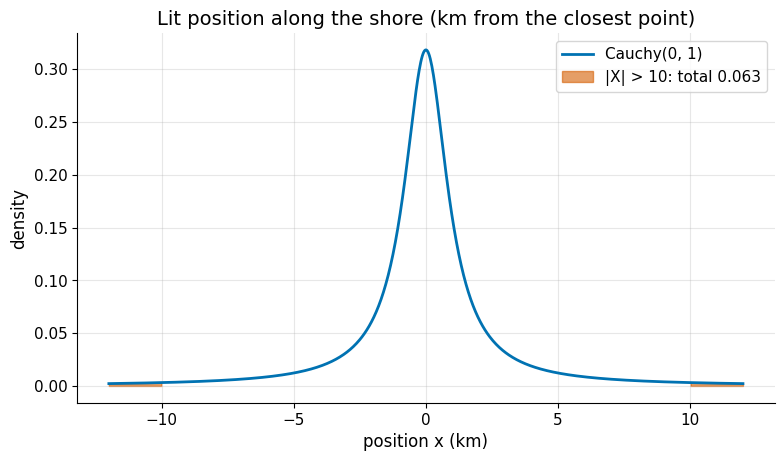

In [20]:
x_axis = np.linspace(-12, 12, 800)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, lighthouse.pdf(x_axis), color=MAIN, linewidth=2, label="Cauchy(0, 1)")
far = np.abs(x_axis) > 10
ax.fill_between(x_axis[x_axis > 10], lighthouse.pdf(x_axis[x_axis > 10]), color=HIGHLIGHT, alpha=0.6, label=f"|X| > 10: total {p_far_hand:.3f}")
ax.fill_between(x_axis[x_axis < -10], lighthouse.pdf(x_axis[x_axis < -10]), color=HIGHLIGHT, alpha=0.6)
ax.set_title("Lit position along the shore (km from the closest point)")
ax.set_xlabel("position x (km)")
ax.set_ylabel("density")
ax.legend()
plt.show()

**Interpretation.** 6 % of flashes land more than 10 km away, and there is no limit to how far a flash can land. **Averaging 1,000 flashes is no more precise than a single flash** (the spread printed above stays 1): there is no "true average position" to converge to. The robust summary is the **median** (or the center of the central half), which does converge.

---
### Example 3: tail risk of daily losses (Normal vs power-law tail)

**Scenario (illustrative).** A portfolio's daily return has SD of **1 %**. We compare two models for the **loss** side: (A) Normal(0, 1 %); (B) a **Pareto tail**: beyond a 2 % loss, exceedances follow a Pareto with $lpha=3$ (a common value for returns), matched so that $P(	ext{loss}>2\%)$ is the same 2.28 % as under (A).

**Questions:** the probability of a loss above 5 %, and how many years apart such days would be (250 trading days per year) under each model.

**By hand.** (A) $P(Z>5)=2.87	imes10^{-7}$: one day in 3.5 million, about once per **13,900 years**. (B) $P(	ext{loss}>5\%)=P(>2\%)	imes(2/5)^3=0.0228	imes0.064=0.00146$: about once per **2.7 years**.

In [21]:
p_over_2_percent = stats.norm(0, 0.01).sf(0.02)
p_over_5_normal = stats.norm(0, 0.01).sf(0.05)
p_over_5_pareto_hand = p_over_2_percent * (0.02 / 0.05) ** 3

tail_model = stats.pareto(b=3, scale=0.02)                        # exceedance of a 2 % loss
p_over_5_pareto_code = p_over_2_percent * tail_model.sf(0.05)
assert np.isclose(p_over_5_pareto_hand, p_over_5_pareto_code)

for name, p in [("Normal", p_over_5_normal), ("Pareto tail (alpha = 3)", p_over_5_pareto_code)]:
    print(f"{name:25s}: P(loss > 5 %) = {p:.3e}, once every {1 / p / 250:,.1f} years")
print(f"the power-law tail makes a 5 % loss {p_over_5_pareto_code / p_over_5_normal:,.0f} times more likely")

simulated_exceedances = 0.02 * rng.uniform(size=2_000_000) ** (-1 / 3)
print(f"simulation of the Pareto exceedance: P(> 5 % | > 2 %) = {np.mean(simulated_exceedances > 0.05):.4f} (theory {(0.02 / 0.05) ** 3:.4f})")

Normal                   : P(loss > 5 %) = 2.867e-07, once every 13,954.2 years
Pareto tail (alpha = 3)  : P(loss > 5 %) = 1.456e-03, once every 2.7 years
the power-law tail makes a 5 % loss 5,079 times more likely
simulation of the Pareto exceedance: P(> 5 % | > 2 %) = 0.0641 (theory 0.0640)


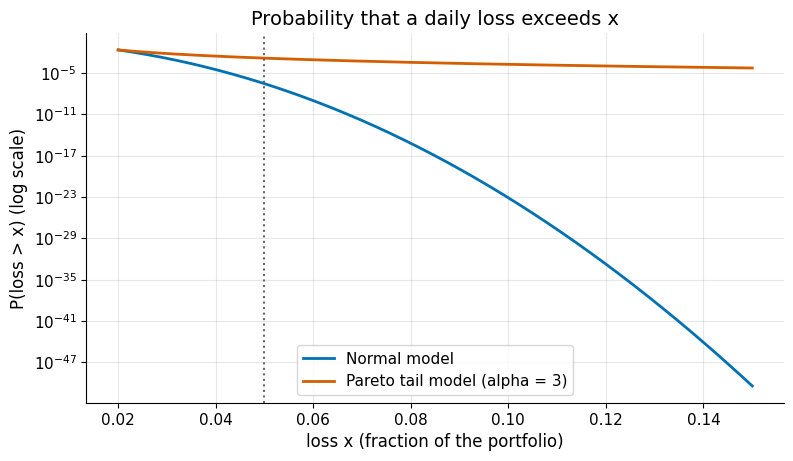

In [22]:
x_axis = np.linspace(0.02, 0.15, 400)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogy(x_axis, stats.norm(0, 0.01).sf(x_axis), color=COLORS[0], linewidth=2, label="Normal model")
ax.semilogy(x_axis, p_over_2_percent * tail_model.sf(x_axis), color=HIGHLIGHT, linewidth=2, label="Pareto tail model (alpha = 3)")
ax.axvline(0.05, color=NEUTRAL, linestyle=":")
ax.set_title("Probability that a daily loss exceeds x")
ax.set_xlabel("loss x (fraction of the portfolio)")
ax.set_ylabel("P(loss > x) (log scale)")
ax.legend()
plt.show()

**Interpretation.** The two models agree on ordinary days but differ by a factor of about **5,000** at a 5 % loss. The Normal says "never in a lifetime"; the power-law tail says "every few years". A risk system built on the Normal would be badly unprepared. **Decision:** use heavy-tailed models (or stress scenarios) for tail risk, and do not extrapolate Normal tails far beyond the data.

## 12. Where it is used

### Statistics
- **Extreme value and tail-index estimation** (Hill estimator, log-log survival plots), peaks-over-threshold models with the generalized Pareto.
- **Robust statistics:** medians and quantile-based methods when moments do not exist; the Cauchy as the stress test for estimators.
- **Cauchy as Student-t(1):** the heaviest-tailed Student-t, used for robust priors and models.

### Data science
- **Popularity, wealth, file and city sizes, web degree distributions:** power laws and the 80/20 rule.
- **Risk and insurance:** claim sizes with Pareto tails; value-at-risk and expected shortfall.
- **Outlier handling:** with heavy tails "outliers" are part of the distribution; do not simply delete them.

### ML and AI
- **Cauchy and Student-t losses and priors** (robust regression, weakly informative priors such as half-Cauchy on scales).
- **Heavy-tailed gradient noise** in SGD and heavy-tailed weight spectra of trained networks (a topic of active research).
- **Long-tailed class distributions** (Zipf/Pareto) in recognition and recommendation benchmarks.

## 13. Common pitfalls and misconceptions

- **Using averages and SDs on heavy-tailed data:** for alpha of 2 or less the SD is infinite; for alpha of 1 or less the mean is infinite. Report medians and quantiles.
- **"The sample mean converges, so the mean exists":** not for the Cauchy (sample means do not converge). A stable-looking running mean on a finite sample can hide an infinite mean.
- **Straight log-log line is not proof of a power law:** the Lognormal also looks straight over a range. Compare alternatives (e.g. with likelihood).
- **`scipy` parameters:** `pareto(b, scale)` uses `b` = alpha and `scale` = x_m (and `loc` = 0 by default); `cauchy(loc, scale)`: neither is a mean or SD.
- **Removing outliers from power-law data** removes the information that matters.
- **Truncation:** real power laws have an upper cutoff; fitting over the right range matters.
- **The Cauchy density is bell shaped:** a bell shape does not imply light tails.

## 14. Exercises

1. For Pareto($\alpha=3$, $x_m=2$): find the mean, the variance and $P(X>10)$.
2. For which $\alpha$ does the Pareto have a finite mean? A finite variance? Explain in one line using the integral test.
3. Insurance claims above 1,000 follow a Pareto with $\alpha=2$. What is the probability a claim exceeds 10,000? Given that a claim exceeds 5,000, what is the probability it exceeds 10,000? (Compare with the first answer: what do you notice?)
4. Compute the Gini coefficient and the share of wealth of the top 10 % for $\alpha=2$.
5. The lighthouse beam position is Cauchy(0, 1). What is the 90th percentile? Use the quantile formula $\tan(\pi(p-\tfrac12))$.
6. Using code, show that the sample variance of 100,000 Pareto($\alpha=1.5$) values keeps changing drastically between independent runs, whereas it is stable for $\alpha=5$.
7. (Harder) Show that if $X\sim\text{Pareto}(\alpha,x_m)$ then for any $c>1$, $P(X>cx\mid X>x)=c^{-\alpha}$ (scale invariance).
8. (Harder) Prove that the ratio $Z_1/Z_2$ of two independent standard normals has the Cauchy(0,1) CDF, using polar coordinates: $\Theta=\arctan(Z_2/Z_1)$ is uniform.

Solutions are at the end.

## 15. Summary table

| Item | Pareto | Cauchy |
|---|---|---|
| Parameters | alpha > 0 (tail index), x_m > 0 (minimum) | x0 (location), gamma > 0 (scale) |
| Support | x >= x_m | all reals |
| Survival | (x_m / x)^alpha | 1/2 - arctan((x - x0)/gamma) / pi |
| Mean | alpha x_m / (alpha - 1) if alpha > 1, else infinite | does not exist |
| Variance | alpha x_m^2 / ((alpha-1)^2 (alpha-2)) if alpha > 2, else infinite | infinite |
| Median | x_m 2^(1/alpha) | x0 |
| When to use | wealth, sizes, losses, popularity; 80/20 | ratios of Normals, resonance, stress-test of robust methods |
| `scipy` name | `stats.pareto(b=alpha, scale=x_m)` | `stats.cauchy(loc=x0, scale=gamma)` |

## Solutions

In [23]:
p1 = stats.pareto(3, scale=2)
print("1: mean", p1.mean(), "var", round(p1.var(), 4), "P(X>10) =", round(p1.sf(10), 5), "= (2/10)^3 =", 0.2**3)
p3 = stats.pareto(2, scale=1000)
print("3: P(>10000) =", p3.sf(10_000), " P(>10000 | >5000) =", p3.sf(10_000) / p3.sf(5_000), "(= 0.25 = (5000/10000)^2)")
print("4: Gini =", 1 / (2 * 2 - 1), " top 10% share =", 0.1 ** ((2 - 1) / 2))
print("5: 90th percentile =", np.tan(np.pi * (0.9 - 0.5)), stats.cauchy.ppf(0.9))
for a in (1.5, 5.0):
    variances = [np.var(rng.uniform(size=100_000) ** (-1 / a)) for _ in range(6)]
    print(f"6: alpha = {a}: sample variances over 6 runs: {np.round(variances, 1)}")

1: mean 3.0 var 3.0 P(X>10) = 0.008 = (2/10)^3 = 0.008000000000000002
3: P(>10000) = 0.01  P(>10000 | >5000) = 0.25 (= 0.25 = (5000/10000)^2)
4: Gini = 0.3333333333333333  top 10% share = 0.31622776601683794
5: 90th percentile = 3.0776835371752527 3.0776835371752544
6: alpha = 1.5: sample variances over 6 runs: [207.8 126.7 138.6 120.1 366.1 346.1]
6: alpha = 5.0: sample variances over 6 runs: [0.1 0.1 0.1 0.1 0.1 0.1]


**1.** Mean $\frac{3\times2}{2}=3$; variance $\frac{3\times4}{4\times1}=3$; $P(X>10)=(2/10)^3=0.008$.

**2.** The mean needs $\int x\cdot x^{-\alpha-1}dx$ to converge: $\alpha>1$. The variance needs $\int x^2x^{-\alpha-1}dx$ to converge: $\alpha>2$.

**3.** $P(>10{,}000)=(1000/10000)^2=0.01$. Given more than 5,000: $(5000/10000)^2=0.25$. A claim that is already large is *much* more likely to become huge: the tail is "scale-free" (see exercise 7), unlike the Exponential, which would forget.

**4.** Gini $=1/(2\alpha-1)=1/3$; top 10 % share $=0.1^{1/2}=0.316$.

**5.** $x_{0.9}=\tan(0.4\pi)=3.078$.

**6.** For $\alpha=1.5$ the sample variances are wildly different from run to run (and are not estimating anything finite); for $\alpha=5$ they agree closely.

**7.** $P(X>cx\mid X>x)=\dfrac{(x_m/(cx))^\alpha}{(x_m/x)^\alpha}=c^{-\alpha}$, independent of $x$.

**8.** $(Z_1,Z_2)$ is rotation invariant, so the angle $\Theta$ is Uniform. $Z_2/Z_1=\tan\Theta$, and for $\Theta$ uniform on an interval of length $\pi$ the CDF of $\tan\Theta$ is $\frac12+\frac1\pi\arctan x$, which is the Cauchy CDF.